# Урок 16. Сколько камер нужно одному пятну

[План курса](../../README_ru.md)

На первом снимке два оранжевых пятна выглядят одинаково. Одно маленькое и близкое, другое крупнее и дальше. Ошибка на фотографии почти нулевая в обоих случаях. Камера немного отъезжает в сторону, и одно пятно съезжает с образца. Это смещение даст обучению информацию о глубине.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "ru"

## Два снимка для обучения, третий для проверки

Левый кадр принадлежит фиксированному образцу на глубине 4, правый строится из текущей сцены. Позиции камер известны заранее. Камера A стоит при X = 0, B — при +0.8, проверочная — при −0.6. Они смотрят параллельно. Переключатель обучения определяет, какие изображения входят в ошибку. Камера для просмотра выбирает только картинку на экране.

При старте глубина модели равна 2.4. У камеры A изображения совпадают ещё до первого шага. У B различие заметно. После двадцати шагов на двух кадрах становится лучше и на третьем, хотя обновления ни разу не использовали его пиксели.

In [2]:
display(demo.experiment(16, "ru"))

## Два способа получить одно оранжевое пятнышко

Сначала оставим открытым только первый затвор. В кадре видна оранжевая середина и постепенный переход в белый фон. Фотография сообщает положение этой середины **на экране**. По ширине перехода можно судить и о размере пятна **в пикселях**. А сколько сантиметров между камерой и объектом? Приблизим к объективу маленький оранжевый шарик, затем заменим его большим и отодвинем. Пока оба закрывают одинаковую часть поля зрения, самого расстояния фотография не выдаёт.

Удобно договориться о масштабе. В этом опыте одну единицу мира считаем метром, глубину отсчитываем вперёд от камеры A. Пиксели нумеруются с нуля, поэтому у изображения шириной 33 крайние центры имеют номера 0 и 32, а середина приходится точно на 16. Номер столбца растёт вправо, номер строки вниз. Значение центра 18.8 допустимо. Мы рисуем вес в целочисленных узлах вокруг этого места. Округление центра до 19 ещё до вычисления весов сделало бы медленное движение похожим на скачки.

Теперь у одного и того же снимка будут две возможные подписи. На первой написано «2.4 м», на второй «4 м». Цвет, поворот, фон и непрозрачность останутся одинаковыми. Переезд **между камерами** и перемещение **модели вдоль луча** — два разных опыта. Чтобы различить причины, сначала держим камеру A на месте и сравниваем обе подписи. Только после этого переносим камеру вправо, сохраняя параметры каждого объекта. Камера B получает два уже разных предсказания ещё до всякого обучения.

## Семейство одинаковых первых кадров

Обозначим неизвестную глубину $z>0$ в единицах мира. Центр модели — $(0.10z,-0.05z,z)$, её три масштаба — $(0.12z,0.08z,0.06z)$. Мы намеренно связали шесть чисел одним параметром. Увеличение $z$ вдвое увеличивает и расстояние, и размер вдвое. Цвет $(0.85,0.20,0.08)$ и непрозрачность $0.9$ закреплены. Камера A смотрит вдоль $+Z$, фокус $f=28$ пикселей, центр кадра $33\times33$ лежит в $(16,16)$.

Горизонтальная координата $u_A=16+28\cdot0.10z/z=18.8$, вертикальная $v_A=16+28\cdot(-0.05)z/z=14.6$. Оба $z$ в дроби сократились. Масштаб по горизонтали тоже содержит отношение $0.12z/z$. Даже поправка из-за протяжённости вдоль глубины не ломает совпадение: все элементы якобиана уменьшаются как $1/z$, а пространственная ковариация растёт как $z^2$. В произведении $J\Sigma J^\mathsf{T}$ два деления на $z$ гасят этот квадрат. Поэтому совпадает **весь след**, включая яркость по краям.

Для $z=2.4$ центр $X=0.24$ и горизонтальный масштаб $0.288$. Для $z=4$ это $0.40$ и $0.48$. Камера A не различает эти сцены при сколь угодно точной оптимизации.

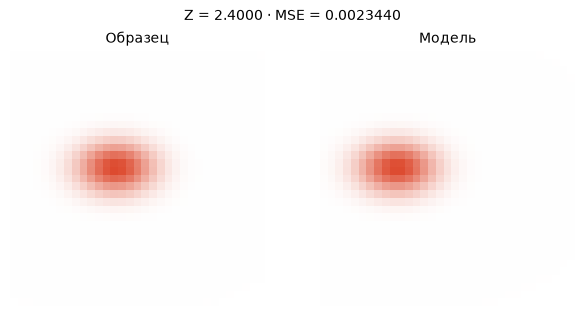

In [3]:
fig = demo.ray_figure("ru")
display(fig)
plt.close(fig)

### Что сократилось в ширине

Совпадение центров ещё оставляло лазейку. Вдруг один след уже другого и цвет по краям выдаст подмену? Вдоль горизонтальной оси у ближней модели один масштаб занимает $28\cdot0.288/2.4=3.36$ пикселя. У дальней $28\cdot0.48/4=3.36$ пикселя. Дальше в расчёт входит ось, уходящая в глубину. Центр немного правее оптической оси, поэтому движение вперёд по этой оси тоже слегка передвигает след влево. Его вклад в горизонтальный масштаб по величине равен $28\cdot0.10\cdot0.06=0.168$ пикселя в обоих случаях. Знак важен при переносе **точки**. Для разброса по независимым осям вклады возводятся в квадрат. Получается $3.36^2+0.168^2=11.317824$ квадратного пикселя у каждой модели.

Почему в коде всё равно вычисляются разные 3D-центры и разные пространственные матрицы? Снимок хранит конечную картинку, а модель обязана ответить ещё и на вопрос о следующем положении наблюдателя. Числа внутри объекта различаются уже сейчас, просто первая камера передаёт их в той комбинации, в которой различие исчезает. Программа, которой дали только этот кадр, может остановиться на совершенно плоском участке ошибки. Долгое обучение ничего к наблюдениям не прибавит.

In [4]:
for z in (2.4, 4.0):
    item = sr.project_splats(sr.ray_scene(z), sr.translated_camera(0), 33, 33)[0]
    print(f"z = {z:.1f}   u = {item['mean'][0]:.2f}   Sxx = {item['covariance'][0,0]:.6f}")
    np.testing.assert_allclose(item["covariance"][0, 0], 3.36**2 + .168**2)

z = 2.4   u = 18.80   Sxx = 11.317824
z = 4.0   u = 18.80   Sxx = 11.317824


## Параллакс можно посчитать до обучения

Если камера B перенесена вправо на $b=0.8$, координата точки в ней $X-b$. Подстановка в перспективу даёт

$$
u_B=16+28(0.10z-b)/z=18.8-28b/z.
$$

У ближней модели $u_B=18.8-22.4/2.4\approx9.467$, у образца $18.8-22.4/4=13.2$. Сдвиг между снимками называют параллаксом. Для образца $u_A-u_B=5.6$ пикселя. Из $u_A-u_B=fb/z$ можно восстановить глубину, когда известны $f,b$ и соответствующие центры: $z=28\cdot0.8/5.6=4$. В настоящей паре изображений сначала пришлось бы выяснить, какие пиксели соответствуют одной точке. У гауссиан вообще нет жёсткого края. Поэтому в опыте сравниваются все пиксели двух кадров.

In [5]:
for z in [2.4, 4.0, 7.0]:
    model = sr.ray_scene(z)
    for baseline in (0, .8, -.6):
        cam = sr.translated_camera(baseline)
        uv = sr.project_splats(model, cam, 33, 33)[0]["mean"]
        print(f"Z={z:g}, Xcam={baseline:+g}: u={uv[0]:.3f}, MSE={sr.ray_loss(z,(baseline,)):.8f}")

Z=2.4, Xcam=+0: u=18.800, MSE=0.00000000
Z=2.4, Xcam=+0.8: u=9.467, MSE=0.00468808
Z=2.4, Xcam=-0.6: u=25.800, MSE=0.00277686
Z=4, Xcam=+0: u=18.800, MSE=0.00000000
Z=4, Xcam=+0.8: u=13.200, MSE=0.00000000
Z=4, Xcam=-0.6: u=23.000, MSE=0.00000000
Z=7, Xcam=+0: u=18.800, MSE=0.00000000
Z=7, Xcam=+0.8: u=15.600, MSE=0.00211890
Z=7, Xcam=-0.6: u=21.200, MSE=0.00121875


### Полпикселя ошибки в измерении

Пусть истинный след оказался между соседними столбцами и при сопоставлении двух картинок разность координат оценили с ошибкой в полпикселя. При нашей базе истинная разность равна 5.6. Сдвиг на полпикселя вверх даст $22.4/6.1\approx3.67$ м, вниз — $22.4/5.1\approx4.39$ м. Получился коридор возможных глубин вокруг настоящих четырёх метров. Его края несимметричны. Когда делитель уменьшается, одна и та же прибавка к нему сильнее меняет результат.

Если движение камеры составило всего 8 сантиметров, то $fb=28\cdot0.08=2.24$, а разность для той же сцены равна $2.24/4=0.56$ пикселя. Ошибка прежняя. Теперь нижняя граница измерения едва больше нуля. В одном случае получим примерно 2.11 м, в другом уже 37.33 м. И в том и в другом случае формула отработала правильно. Так выглядит недостаток геометрической информации в самих исходных данных.

У большой базы тоже есть цена. При съёмке объекта с двух очень разных сторон некоторые детали скрываются и перестают быть общей меткой. Поэтому при выборе снимка для будущей проверки важен не только угол. Есть ли в кадре сам объект? Известны ли поза камеры и фокус? Достаточно ли различаются наблюдения, чтобы две гипотезы дали заметно разные изображения? В нашем стенде все три положения известны до подгонки, а единственное пятно остаётся видимым.

In [6]:
for baseline in (.8, .08):
    disparity = 28*baseline/4
    estimates = [28*baseline/(disparity+e) for e in (-.5, 0, .5)]
    print(f"b = {baseline:.2f} m, d = {disparity:.2f} px   z =", np.round(estimates, 3))

b = 0.80 m, d = 5.60 px   z = [4.392 4.    3.672]
b = 0.08 m, d = 0.56 px   z = [37.333  4.     2.113]


## Один настоящий шаг по ошибке

Пусть $L_A,L_B$ — средние квадраты разностей RGB из урока 6. Для одного вида знаменатель $33\cdot33\cdot3=3267$ чисел. В начале $L_A$ равна нулю с точностью вычислений, $L_B\approx0.00468808$. Берём одинаковый вес для камер: $L=(L_A+L_B)/2\approx0.00234404$. Отложенный снимок в эту сумму не входит.

Есть только одно неизвестное число $z$. Для проверки производной строим два соседних варианта, $z-h$ и $z+h$, где $h=0.002$ единицы мира. Знаменатель при вычислении наклона — расстояние между этими вариантами, $2h=0.004$.

$$
\begin{aligned}
g &\approx \frac{L(2.402)-L(2.398)}{0.004}\\
  &\approx (0.0023357144-0.0023523820)/0.004=-0.004167.
\end{aligned}
$$

Минус говорит, что небольшое увеличение глубины здесь уменьшает ошибку. При размере шага $\eta=80$ получим $z_{\rm new}=2.4-80(-0.004167)\approx2.73335$. Размер шага переводит наклон в сдвиг глубины; число 80 относится к этой шкале ошибки. Для защиты от ухода за камеру глубина ограничена интервалом от 1.25 до 7. После двадцати таких шагов $z\approx3.8101$. Проверочная ошибка снижается с $0.00277686$ до $0.00001703$. При обучении только на A график практически плоский.

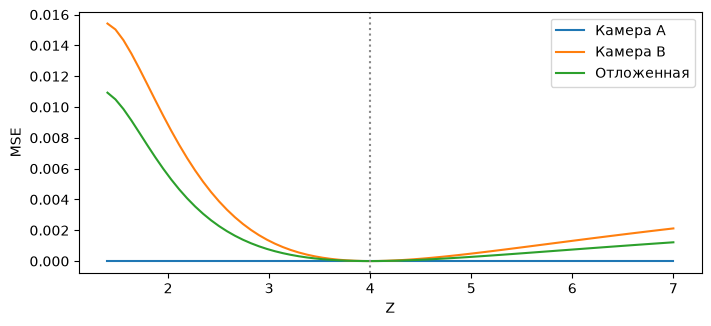

In [7]:
fig = demo.ray_landscape("ru")
display(fig)
plt.close(fig)

In [8]:
z = 2.4
for step in range(20):
    z, gradient = sr.depth_step(z, (0,.8))
print(round(z, 6), sr.ray_loss(z, (0,.8)), sr.ray_loss(z, (-.6,)))
assert sr.ray_loss(z, (-.6,)) < sr.ray_loss(2.4, (-.6,))

3.810089 1.5238536519958356e-05 1.70260316191234e-05


## Как голосует один пиксель

До сих пор наклон ошибки получался как число из двух соседних рендеров. Заглянем в это число. Камера B, строка 15, столбец 14. У образца здесь оранжевая середина, у ближней модели — более светлый край. Возьмём синий канал, потому что при переходе от белого к оранжевому именно он сильно темнеет. Его значение $I=0.66766$, у образца $Y=0.20773$. Оба в диапазоне от нуля до единицы, остаток $r=I-Y=+0.45993$. Плюс означает лишнюю синюю яркость. Один квадрат этого остатка добавляет около $0.21154$ к сумме по кадру, до деления на число измерений.

Глубина немного выросла. Центр модели сдвинулся вправо, и в выбранный пиксель попала более густая часть пятна. Оценим изменение яркости по рендерам при 2.398 и 2.402 м. За один метр синий канал здесь менялся бы примерно на $-0.50675$, **если бы** местный наклон сохранялся так долго. Сам замер сделан всего на четырёх миллиметрах. Умножение этого наклона на небольшой сдвиг глубины даёт изменение яркости, а ещё одно умножение на $2r$ даёт изменение квадрата. Множитель 2 следует из раскрытия $(r+\delta)^2-r^2=2r\delta+\delta^2$. После деления на маленькое $\delta$ вторая часть стремится к нулю.

$$
\begin{aligned}
g_{\rm pixel}&=\frac{2(I-Y)}{3267}\frac{\Delta I}{\Delta z}\\
&\approx\frac{2\cdot0.45993}{3267}\cdot(-0.50675)
\approx-0.00014268.
\end{aligned}
$$

Это голос одного канала одного пикселя камеры B в производной её средней ошибки по глубине. Соседние пиксели могут голосовать в другую сторону. В столбце 10 той же строки синий канал модели уже слишком тёмный. Дальнейшее затемнение там нежелательно, поэтому вклад положительный, около $+0.00002545$. Карта ниже складывает три таких голоса **со знаком** в каждой точке. Белый фон вдали почти ничего не сообщает о глубине. Сильные голоса лежат там, где цвет меняется при сдвиге силуэта. По всей камере выходит примерно $-0.008334$. Деление на две обучающие камеры даёт знакомые $-0.004167$, поскольку вклад A вдоль нашего семейства равен нулю.

В коде есть ещё одна проверка. Тот же кадр строится из тензоров. Цепочка от глубины до каждого цвета остаётся внутри PyTorch, включая изменение ширины и проекцию. Обратный проход складывает вклады всех каналов по правилам производных. Два независимых способа измеряют один наклон. Они могут слегка различаться на последних знаках из-за конечной длины шага в первом способе.

B[15,14,blue]: -0.00014268   B total: -0.00833378
PyTorch: -0.0083338


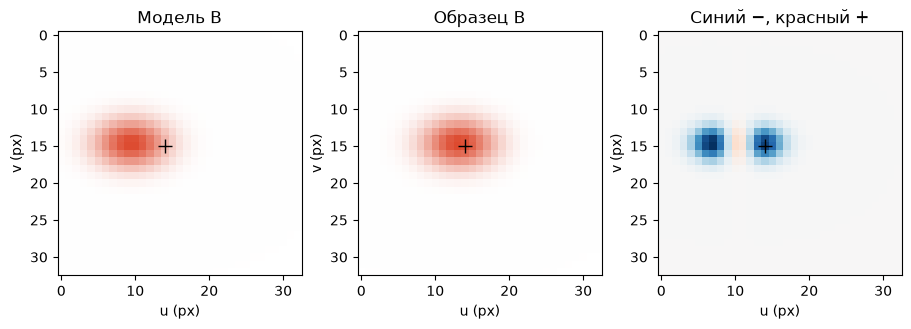

In [9]:
from splat_fit import render_parallel
import torch

cam_b = sr.translated_camera(.8)
def frame_at(z):
    return sr.render_scene(sr.ray_scene(z), cam_b, 33, 33)

prediction, target = frame_at(2.4), frame_at(4)
h = .002
slope = (frame_at(2.4+h)-frame_at(2.4-h))/(2*h)
votes = 2*(prediction-target)*slope/prediction.size
print("B[15,14,blue]:", round(votes[15,14,2], 8), "  B total:", round(votes.sum(), 8))

z = torch.tensor(2.4, dtype=torch.float64, requires_grad=True)
centers = z*z.new_tensor([[.10,-.05,1.]])
scales = z*z.new_tensor([[.12,.08,.06]])
tensor_frame = render_parallel(centers, scales, z.new_tensor([[.85,.2,.08]]),
                               z.new_tensor([.9]), .8)
(tensor_frame-torch.as_tensor(target)).square().mean().backward()
print("PyTorch:", round(z.grad.item(), 8))
np.testing.assert_allclose(votes.sum(), z.grad.item(), rtol=2e-5)

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), constrained_layout=True)
axes[0].imshow(prediction); axes[1].imshow(target)
signed = votes.sum(axis=2)
limit = np.abs(signed).max()
axes[2].imshow(signed, cmap="RdBu_r", vmin=-limit, vmax=limit)
titles = (["Модель B", "Образец B", "Синий −, красный +"] if lang=="ru"
          else ["B prediction", "B target", "Blue −, red +"])
for ax, title in zip(axes, titles):
    ax.set_title(title); ax.set_xlabel("u (px)"); ax.set_ylabel("v (px)")
    ax.plot(14,15,"+",color="black",ms=10)
plt.show()

## Из одного параметра — в сцену из двух гауссиан

Теперь отвяжем положение от ширины. В отдельном опыте два пятна имеют собственные центры и RGB, шесть чисел на каждое. Масштабы, повороты, непрозрачности и калибровка камер известны. На входе две цветные картинки с камер при $X=-0.8$ и $+0.65$. Третья камера при $+0.12$ даёт проверочный ракурс. Из неё построены все три картинки ниже.

Программа строит проекции, смешивает пятна и усредняет ошибки **только первых двух** кадров. В PyTorch цвет и центр остаются связанными со значениями пикселей вычислительной цепочкой. Вызов `backward()` возвращает для каждого из 12 чисел скорость изменения общего loss, как в уроке 8. Здесь шаги подбирает Adam. Он помнит среднее направление и средний квадрат прошлых градиентов для каждого числа, чтобы подстраивать длину его шага. Индексы отсортированных слоёв фиксированы на отдельном шаге; в точке перестановки порядок дискретен. После обновления RGB ограничен от 0 до 1, глубина от 1.25 до 7.

Обучение начинается с неточных центров и приглушённых цветов. За 45 шагов проверочная MSE падает примерно с $0.002427$ до $0.00000827$. Низкая ошибка на ещё одной картинке проверяет предсказание в этом ракурсе. У невидимых сторон и заслонённых деталей по-прежнему нет измерений.

In [10]:
import torch
from splat_fit import train_two_splats
torch.set_num_threads(1)
run = train_two_splats(45)
print(np.array(run["history"])[[0, 15, 45]])
assert run["history"][-1][1] < run["history"][0][1] / 100

[[2.35787013e-03 2.42663412e-03]
 [1.26140177e-04 1.16656163e-04]
 [9.42653280e-06 8.26944021e-06]]


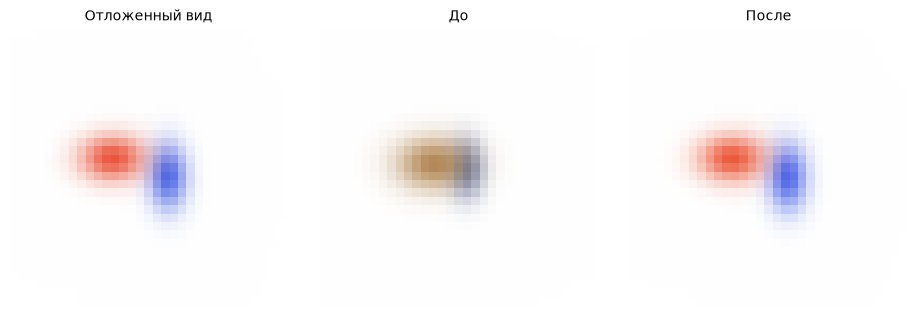

In [11]:
fig = demo.panel([run["target"],run["before"],run["after"]], ["Отложенный вид","До","После"])
display(fig)
plt.close(fig)

### Что именно исправил второй опыт

У двух пятен теперь 12 ручек вместо одной. Каждому центру принадлежат три числа в метрах. Каждому цвету принадлежат три доли без единиц. Одинаковое число в градиенте цвета и в градиенте глубины описывало бы разные изменения. В оптимизатор передаётся конкретный массив каждого типа, и история шагов хранится отдельно для каждого его элемента. У наблюдений тоже есть форма. Два кадра по 33 строки, 33 столбца и три канала дают $2\cdot33\cdot33\cdot3=6534$ чисел. Это не 6534 независимых уравнения для геометрии. Тысячи соседних значений могут описывать один и тот же белый фон.

В первом опыте у модели не было выбора между изменением цвета и изменением площади. Теперь такой выбор есть. За пределами пятна на белом фоне модель может уменьшить ошибку, сдвинув лишний цвет обратно к объекту. Ещё она может просто приблизить свой цвет к белому. Во втором случае промах на фоне уменьшится, но внутри силуэта появится слишком светлая область. Остальные пиксели и вторая камера предъявят ей счёт. На картинке «До» полезно отделить два признака. Сместившийся контур указывает на геометрию. Ошибка даже в той части, где контуры совпадают, может приходить от цвета или непрозрачности.

Три изображения мы синтезировали сами, поэтому известен и ответ для проверки. При работе с фотографиями истинные 3D-центры недоступны. Их заменяет честно отложенная камера. Если после каждого шага смотреть на её ошибку и именно по ней выбирать лучший набор настроек, эта камера уже участвует в выборе. Для окончательной оценки тогда потребуется ещё один снимок. Здесь число шагов задано заранее, проверочная кривая только записывается. В следующем опыте встретится другая причина упорной ошибки. Даже при правильных камерах и совершенно чистом фоне у одного пятна может просто не хватить вершин, чтобы изобразить две отдельные детали.

## Опыты и разбор

Поможет ли вторая фотография из той же точки, если первая уже совпала? Что станет с различимостью глубин при совсем маленьком смещении камеры?

<details><summary>Разбор</summary>

Вторая копия A удвоит число измерений и знаменатель среднего, но оставит ту же плоскую зависимость от глубины. При $b=0.008$ вместо $0.8$ разность центров между гипотезами 2.4 и 4 составит всего $3.733/100\approx0.037$ пикселя. Теоретическая разница есть; на реальных снимках её легче потерять из-за шума, смаза и ошибки позы.

</details>

### Другая ширина кадра

К обеим картинкам добавили белую рамку, сохранив прежние пиксели и их проекции без изменений. Теперь в кадре ровно вдвое больше цветовых значений, и во всей добавленной области модель совпадает с образцом. Что произойдёт с MSE и с первым шагом по глубине при прежнем размере шага?

<details><summary>Разбор про рамку</summary>

В числителе прибавилась сумма нулей. Знаменатель удвоился, поэтому ошибка и её производная уменьшились вдвое. При старом размере шага 80 сдвиг глубины будет около $0.33335/2=0.16668$ м. Геометрическая информация внутри прежней картинки сохранилась. Изменилась нормировка, через которую эта информация управляет длиной обновления. Рамка должна действительно добавлять совпадающие значения для всех соседних глубин, иначе её собственный вклад в производную придётся посчитать.

</details>

### У камеры перепутали сторону

Пятно в A имеет $u_A=18.8$, в B — $u_B=13.2$. В файл камеры записали $b=-0.8$ м. Какая глубина выйдет из двух отметок? Как это связано с ограничением $z>0$?

<details><summary>Разбор про знак базы</summary>

Разность $18.8-13.2=+5.6$ пикселя. Числитель $28(-0.8)=-22.4$, глубина $-22.4/5.6=-4$ м. В принятой системе камера смотрит вперёд вдоль положительного Z. Положительная глубина не может согласовать эти две отметки при таком знаке базы. Прежде чем менять скорость обучения, есть смысл сверить направление переноса и порядок вычитания кадров. Перестановка обеих камер поменяла бы и знак базы, и знак разности, сохранив прежний ответ.

</details>

### Чей это градиент

У одной камеры наклон ошибки по глубине $+0.002$, у второй $-0.008$. Изображения одинакового размера, веса камер равны. Куда двинется глубина при размере шага 10? А если второй камере случайно дали вес ноль?

<details><summary>Разбор про два голоса</summary>

Равные веса дают $(0.002-0.008)/2=-0.003$. Правило спуска вычитает наклон, поэтому глубина увеличится на $0.03$ м. Если средняя ошибка считается только по первой камере, наклон становится $+0.002$, а глубина уменьшается на $0.02$ м. У одной пары кадров сигналы вполне могут спорить. Знак вклада определяется тем, что произошло с конкретным изображением при смещении пробной модели.

</details>